In [1]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score
)
import numpy as np
import tensorflow as tf
from keras import layers
import pandas as pd

def evaluate_model(y_true, y_pred, scores, time, threshold=0.2, model_name="Model"):
    """
    Evaluates a model and returns metrics formatted for copy-pasting.
    
    Parameters:
        y_true (np.array): Ground truth labels (0=normal, 1=anomaly).
        scores (np.array): Anomaly scores (lower = more anomalous).
        threshold (float): Threshold for anomaly decision.
        model_name (str): Name of the model.
        
    Returns:
        dict: Dictionary of metrics (can print or format for LaTeX).
    """

    precision = precision_score(y_true, y_pred, zero_division=0)
    accuracy = accuracy_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    auroc = roc_auc_score(y_true, scores)

    cm = confusion_matrix(y_true, y_pred)
    clf_report = classification_report(y_true, y_pred, digits=2)

    result = {
        "Model": model_name,
        "Precision": f"{precision:.3f}",
        "Accuracy": f"{accuracy:.3f}",
        "Recall": f"{recall:.3f}",
        "F1-Score": f"{f1:.3f}",
        "Matrix": f"TP={cm[1,1]}, FP={cm[0,1]}, FN={cm[1,0]}, TN={cm[0,0]}",
        "AUROC": f"{auroc:.3f}",
        "Data Loading + Inference Time (s)": f"{time:.4f}s",
        "Clf Report": clf_report.strip()
    }

    return result


2025-08-15 16:14:42.824139: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-08-15 16:14:42.960357: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
transformed_training_data = pd.read_csv('Dataset/Transformed/Normalised/labelled_transformed_training_data.csv')

# 1. Extract labels (column 6)
training_labels = transformed_training_data.iloc[:, 6].astype(bool)  # Anomalies: True

# 2. Drop label and extra column (column 6 and 7)
training_data = transformed_training_data.drop(
    columns=[transformed_training_data.columns[6], transformed_training_data.columns[7]]
)

# 3. Convert to float32 tensor
training_data = tf.convert_to_tensor(training_data.values, dtype=tf.float32)

# 4. Convert labels to tensor (bool)
training_labels = tf.convert_to_tensor(training_labels.values, dtype=tf.bool)

# 5. Split normal vs anomalous
normal_training_data = tf.boolean_mask(training_data, ~training_labels)
anomalous_training_data = tf.boolean_mask(training_data, training_labels)

In [3]:
transformed_testing_data = pd.read_csv('Dataset/Transformed/Normalised/labelled_transformed_testing_data.csv')

# 1. Extract labels (column 6)
testing_labels = transformed_testing_data.iloc[:, 6].astype(bool)  # Anomalies: True

# 2. Drop label and extra column (column 6 and 7)
testing_data = transformed_testing_data.drop(
    columns=[transformed_testing_data.columns[6], transformed_testing_data.columns[7]]
)

# 3. Convert to float32 tensor
testing_data = tf.convert_to_tensor(testing_data.values, dtype=tf.float32)

# 4. Convert labels to tensor (bool)
testing_labels = tf.convert_to_tensor(testing_labels.values, dtype=tf.bool)

# 5. Split normal vs anomalous
normal_testing_data = tf.boolean_mask(testing_data, ~testing_labels)
anomalous_testing_data = tf.boolean_mask(testing_data, testing_labels)

In [4]:
transformed_validation_data = pd.read_csv('Dataset/Transformed/Normalised/labelled_transformed_validation_data.csv')

# 1. Extract labels (column 6)
validation_labels = transformed_validation_data.iloc[:, 6].astype(bool)  # Anomalies: True

# 2. Drop label and extra column (column 6 and 7)
validation_data = transformed_validation_data.drop(
    columns=[transformed_validation_data.columns[6], transformed_validation_data.columns[7]]
)

# 3. Convert to float32 tensor
validation_data = tf.convert_to_tensor(validation_data.values, dtype=tf.float32)

# 4. Convert labels to tensor (bool)
validation_labels = tf.convert_to_tensor(validation_labels.values, dtype=tf.bool)

# 5. Split normal vs anomalous
normal_validation_data = tf.boolean_mask(validation_data, ~validation_labels)
anomalous_validation_data = tf.boolean_mask(validation_data, validation_labels)

In [5]:
from qiskit.qpy import load

model_name = "8f_qae_dense_ra2_5k"
model_path = "Models/QAE/First_N/"

with open(f"{model_path + model_name}/ae.qpy", "rb") as f:
    ae = load(f)[0]  # returns a list of circuits
    
weight_names = np.load(f"{model_path + model_name}/weight_param_names.npy", allow_pickle=True)
weight_params = [p for p in ae.parameters if p.name in weight_names]
trained_params = np.load(f"{model_path + model_name}/trained_parameters.npy")

In [6]:
import time
from sklearn.preprocessing import MinMaxScaler

start_time = time.time()

reduced_testing_data = testing_data
scaler = MinMaxScaler(feature_range=(0, np.pi))
scaled_testing_data = scaler.fit_transform(reduced_testing_data)

reduced_normal_training_data = normal_training_data
scaler = MinMaxScaler(feature_range=(0, np.pi))
scaled_normal_training_data = scaler.fit_transform(reduced_normal_training_data)

In [8]:
from qiskit_ibm_runtime import QiskitRuntimeService


# service = QiskitRuntimeService.save_account(
#     token="Uf1Q38KVAXRx6jatO3HJpMUjxV1tJwntrYuu7eIAeg1O", # IBM Cloud API key.
#     instance="crn:v1:bluemix:public:quantum-computing:us-east:a/ba89a683d067413b99e1307eef39d3c0:463708b7-53cb-4347-8882-994c36021e6b::",
#     set_as_default=True, # Optionally set these as your default credentials.
# )

service = QiskitRuntimeService()
backend = service.least_busy(simulator=False, operational=True)

In [11]:
from qiskit_machine_learning.neural_networks import SamplerQNN
from qiskit.primitives import StatevectorSampler as Sampler
from qiskit_aer.primitives import Sampler
from qiskit import QuantumCircuit
from qiskit_ibm_runtime import QiskitRuntimeService

sampler = Sampler(run_options={"mode": backend})

# Constants
num_latent = 2
num_trash = 2
total_qubits = num_latent + 2 * num_trash + 1  # encoding + reference + auxiliary

dummy_encoding = QuantumCircuit(total_qubits)
qc_full = dummy_encoding.compose(ae)

qnn = SamplerQNN(
    circuit=qc_full,
    input_params=[],                     # No input parameters — encoding is done externally
    weight_params=weight_params,         # Only train the parameters of the AE
    output_shape=2,                      # Binary outcome (0 or 1 from SWAP test)
    interpret=lambda x: x,               # Identity function, optional
    sampler=sampler
)

/tmp/ipykernel_53856/4267520553.py:17: DeprecationWarning: V1 Primitives are deprecated as of qiskit-machine-learning 0.8.0 and will be removed no sooner than 4 months after the release date. Use V2 primitives for continued compatibility and support.
  qnn = SamplerQNN(


In [12]:
from qiskit.circuit import QuantumCircuit, ParameterVector
from qiskit.circuit.library import EfficientSU2, RealAmplitudes
import numpy as np
from qiskit import QuantumRegister, ClassicalRegister
from qiskit.circuit.library import efficient_su2, real_amplitudes, pauli_two_design

def dense_angle_encoding(x):
    num_qubits = len(x) // 2
    circuit = QuantumCircuit(num_qubits)
    for i in range(num_qubits):
        circuit.ry(x[2 * i], i)
        circuit.rz(x[2 * i + 1], i)
    return circuit


def build_encoded_circuits(data, encoding_fn):
    circuits = []
    for x in data:
        circuit = encoding_fn(x)
        circuits.append(circuit)
    return circuits

In [18]:
from tqdm import tqdm
from qiskit import transpile

def compute_anomaly_scores(ae, qnn, input_data, trained_params, encoding_fn, batch_size=64, backend=None, optimization_level=1):
    scores = []
    total_qubits = num_latent + 2 * num_trash + 1
    num_encoding_qubits = num_latent + num_trash

    ae = ae.assign_parameters({p: v for p, v in zip(ae.parameters, trained_params)})

    start = time.time()
    for i in tqdm(range(0, len(input_data), batch_size), desc="Running inference"):
        batch = input_data[i : i + batch_size]
        circuits = []

        for x in batch:
            qc = QuantumCircuit(total_qubits, 1)
            input_slice = x[:2 * num_encoding_qubits]
            encoded = encoding_fn(input_slice)
            qc.compose(encoded, qubits=range(encoded.num_qubits), inplace=True)
            qc.compose(ae, inplace=True)

            # Transpile if a backend is provided
            if backend is not None:
                qc = transpile(qc, backend=backend, optimization_level=optimization_level)

            circuits.append(qc)

        job = qnn.sampler.run(circuits)
        result = job.result()

        for quasi in result.quasi_dists:
            p1 = quasi.get(1, 0)
            scores.append(p1)

    elapsed = time.time() - start
    print(f"\nAll batches processed in {elapsed:.4f} seconds.")

    return np.array(scores), elapsed



In [22]:
subset_size = 1000
# subset_indices = np.random.choice(len(scaled_normal_training_data), size=subset_size, replace=False)
# training_subset = scaled_normal_training_data[subset_indices]
training_subset = scaled_normal_training_data[:subset_size]

# train_scores, train_time = compute_anomaly_scores(
#     ae,
#     qnn,
#     training_subset,
#     trained_params,
#     encoding_fn=dense_angle_encoding,
#     batch_size=64,
#     backend=backend
# )

# threshold = 0.5 * (np.min(train_scores) + np.max(train_scores))
threshold = 0.25244140625

print(f"Threshold: {threshold}")

Threshold: 0.25244140625


In [23]:
# import matplotlib.pyplot as plt

# # --- Histogram of scores ---
# plt.hist(train_scores, bins=30, alpha=0.5, label='Normal')
# plt.axvline(threshold, color='red', linestyle='--', label=f"Threshold = {threshold:.3f}")
# plt.xlabel("Anomaly Score (Swap Test Failure Probability)")
# plt.ylabel("Number of Samples")
# plt.title("Anomaly Score Distribution")
# plt.legend()
# plt.show()

In [ ]:
scores, elapsed_time = compute_anomaly_scores(
    ae,
    qnn,
    scaled_testing_data,
    trained_params,
    encoding_fn=dense_angle_encoding,
    batch_size=64,
    backend=backend
)


Running inference:   0%|                     | 7/2953 [01:27<9:37:32, 11.76s/it]

Running inference: 100%|████████████████████| 2953/2953 [27:17<00:00,  1.80it/s]



All batches processed in 1637.4897 seconds.
Model: 8f_qae_dense_ra2_5k
Precision: 1.000
Accuracy: 0.946
Recall: 0.941
F1-Score: 0.969
Matrix: TP=161313, FP=57, FN=10146, TN=17451
AUROC: 0.965
Data Loading + Inference Time (s): 1637.4897s
Clf Report: precision    recall  f1-score   support

           0       0.63      1.00      0.77     17508
           1       1.00      0.94      0.97    171459

    accuracy                           0.95    188967
   macro avg       0.82      0.97      0.87    188967
weighted avg       0.97      0.95      0.95    188967


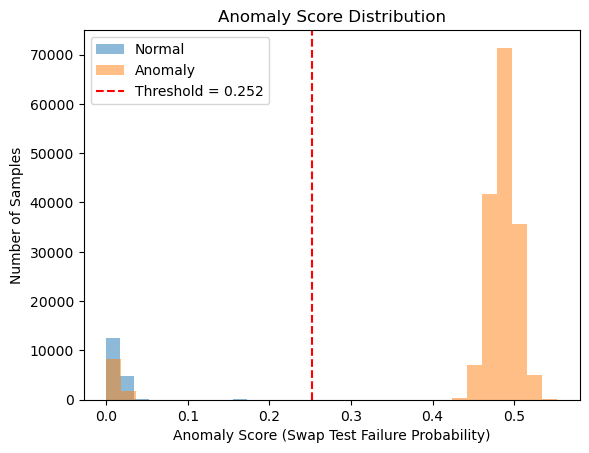

In [26]:
y_pred = (scores > threshold).astype(int)
y_true = np.array(testing_labels).astype(int)[:len(scores)]

metrics = evaluate_model(
    y_true=y_true,
    y_pred=y_pred,
    scores=scores,
    time=elapsed_time,
    threshold=threshold,  # same threshold used in predict
    model_name=model_name
)

# Print clean table row for your notes
for k, v in metrics.items():
    print(f"{k}: {v}")

# --- Histogram of scores ---
plt.hist(scores[y_true == 0], bins=30, alpha=0.5, label='Normal')
plt.hist(scores[y_true == 1], bins=30, alpha=0.5, label='Anomaly')
plt.axvline(threshold, color='red', linestyle='--', label=f"Threshold = {threshold:.3f}")
plt.xlabel("Anomaly Score (Swap Test Failure Probability)")
plt.ylabel("Number of Samples")
plt.title("Anomaly Score Distribution")
plt.legend()
plt.show()
